In [85]:
import os
import re
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from datasets import load_dataset, Video


import gymnasium as gym
from gymnasium import spaces
from ultralytics import YOLO
from stable_baselines3 import DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback, EvalCallback
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize

from sklearn.model_selection import train_test_split

import cv2
import torchvision.transforms as T_img
from torchvision.models import resnet18, ResNet18_Weights


In [86]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ device: {device}")
if device.type == 'cuda':
    print(f"   gpu: {torch.cuda.get_device_name(0)}")

✅ device: cuda
   gpu: NVIDIA GeForce RTX 3050 Ti Laptop GPU


## PART 2 — استخراج ویژگی YOLO

از هر فریم، YOLOv8n این ۵ ویژگی رو استخراج می‌کنه:
- تعداد ماشین‌ها
- فاصله‌ی نزدیک‌ترین ماشین در چپ / مرکز / راست
- تعداد ماشین‌های نزدیک (< ۱۵ متر)

**idempotent:** اگه فایل‌ها موجود باشن، دوباره اجرا نمی‌شه.

In [87]:
TRAIN_RAW_DIR  = r'C:\Users\pourya\Desktop\high\train_streaming_1000'
TEST_RAW_DIR   = r'C:\Users\pourya\Desktop\high\test_streaming_200'
YOLO_TRAIN_DIR = './yolo_train'
YOLO_TEST_DIR  = './yolo_test'

N_TRAIN_EXPECTED = 1000
N_TEST_EXPECTED  = 200
BATCH_SIZE       = 16
VEHICLE_CLASSES  = [2, 3, 5, 7]  # car, motorcycle, bus, truck


def _count_npz(d):
    if not os.path.isdir(d):
        return 0
    return len([f for f in os.listdir(d) if f.endswith('.npz')])


def _extract_yolo_features(frames, yolo, device_arg, batch_size=BATCH_SIZE):
    # frames: (T, 3, 224, 224) uint8
    # خروجی: (T, 5) → [n_veh, min_d_c, min_d_l, min_d_r, n_close]
    T = len(frames)
    imgs = [frames[i].permute(1, 2, 0).numpy() for i in range(T)]
    feats = []

    for i in range(0, T, batch_size):
        batch = imgs[i:i + batch_size]
        results = yolo(batch, imgsz=320, device=device_arg, verbose=False)
        for r in results:
            n_veh = 0
            min_dc = min_dl = min_dr = 50.0
            n_close = 0
            H, W = r.orig_shape
            for box in r.boxes:
                if int(box.cls[0]) not in VEHICLE_CLASSES:
                    continue
                n_veh += 1
                x1, y1, x2, y2 = box.xyxy[0].tolist()
                cx = (x1 + x2) / 2
                area_frac = ((x2 - x1) * (y2 - y1)) / (W * H)
                # ماشین بزرگ‌تر = نزدیک‌تر
                dist = 50.0 * max(0.0, 1.0 - np.sqrt(area_frac) * 3.0)
                if cx < W / 3:
                    min_dl = min(min_dl, dist)
                elif cx > 2 * W / 3:
                    min_dr = min(min_dr, dist)
                else:
                    min_dc = min(min_dc, dist)
                if dist < 15:
                    n_close += 1
            feats.append([n_veh, min_dc, min_dl, min_dr, n_close])

    return np.array(feats, dtype=np.float32)


def _process_dir(src_dir, dst_dir, yolo, device_arg):
    os.makedirs(dst_dir, exist_ok=True)
    if not os.path.isdir(src_dir):
        print(f"⚠️  مسیر پیدا نشد: {src_dir}")
        return
    files = sorted([f for f in os.listdir(src_dir) if f.endswith('.pt')])
    skipped = 0
    for fname in tqdm(files, desc=os.path.basename(dst_dir)):
        out_path = os.path.join(dst_dir, fname.replace('.pt', '.npz'))
        if os.path.exists(out_path):
            skipped += 1
            continue
        frames = torch.load(os.path.join(src_dir, fname), weights_only=True)
        if frames.dtype != torch.uint8:
            frames = (frames * 255).clamp(0, 255).to(torch.uint8)
        feats = _extract_yolo_features(frames, yolo, device_arg)
        np.savez(out_path, yolo_feats=feats)
    print(f"  → {len(files)} فایل، {skipped} skip، {len(files)-skipped} استخراج شد")


# ---- منطق اجرا ----
n_train = _count_npz(YOLO_TRAIN_DIR)
n_test  = _count_npz(YOLO_TEST_DIR)
print(f"📂 yolo_train: {n_train}/{N_TRAIN_EXPECTED}")
print(f"📂 yolo_test:  {n_test}/{N_TEST_EXPECTED}")

need_train = n_train < N_TRAIN_EXPECTED
need_test  = n_test  < N_TEST_EXPECTED

if not need_train and not need_test:
    print("✅ YOLO features کامل موجودن")
else:
    device_arg = 0 if torch.cuda.is_available() else 'cpu'
    print(f"🔧 device: {device_arg}")
    yolo = YOLO('yolov8n.pt')
    if device_arg == 0:
        yolo.to('cuda')
    if need_train:
        _process_dir(TRAIN_RAW_DIR, YOLO_TRAIN_DIR, yolo, device_arg)
    if need_test:
        _process_dir(TEST_RAW_DIR, YOLO_TEST_DIR, yolo, device_arg)
    print("✅ تمام شد")

print(f"\n📊 نهایی: train={_count_npz(YOLO_TRAIN_DIR)}, test={_count_npz(YOLO_TEST_DIR)}")

📂 yolo_train: 1000/1000
📂 yolo_test:  200/200
✅ YOLO features کامل موجودن

📊 نهایی: train=1000, test=200


In [88]:
sample = np.load('./yolo_train/' + os.listdir('./yolo_train')[0])
f = sample['yolo_feats']
print(f"shape: {f.shape}  (باید T,5 باشه)")
print(f"n_veh mean:  {f[:,0].mean():.2f}")
print(f"min_d_c mean: {f[:,1].mean():.2f}")
print(f"n_close mean: {f[:,4].mean():.2f}")

shape: (203, 5)  (باید T,5 باشه)
n_veh mean:  4.31
min_d_c mean: 13.05
n_close mean: 1.28


## PART 3 — LSTM + تولید risk

- بارگذاری LSTM آموزش‌دیده (F1=0.73 در dump5)
- محاسبه‌ی risk در هر لحظه — **causal** (فقط از گذشته، بدون نشت اطلاعات آینده)
- استخراج `event_frame` از metadata Nexar

**تفکیک:** accident ~0.61 / normal ~0.52 → تفاوت ۰.۰۸ (متوسط، محدودیت LSTM).

In [89]:
TRAIN_FEATURES_DIR = './train_features'
TEST_FEATURES_DIR  = './test_features'
LSTM_PATH          = './best_final_lstm_oneway.pth'

assert os.path.isdir(TRAIN_FEATURES_DIR), "train_features نیست!"
assert os.path.isdir(TEST_FEATURES_DIR),  "test_features نیست!"
assert os.path.isfile(LSTM_PATH),         "best_final_lstm_oneway.pth نیست!"

n_ft = len([f for f in os.listdir(TRAIN_FEATURES_DIR) if f.endswith('.pt')])
print(f"✅ train_features: {n_ft} فایل")


class AccidentLSTM(nn.Module):
    def __init__(self, input_size=512, hidden_size=128, num_layers=1, dropout=0.4):
        super(AccidentLSTM, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True,
                            dropout=dropout if num_layers > 1 else 0,
                            bidirectional=False)
        self.fc1 = nn.Linear(hidden_size, 64)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(64, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        mask = (x.abs().sum(dim=-1) > 0).unsqueeze(-1)
        lstm_out, _ = self.lstm(x)
        lstm_out = lstm_out.masked_fill(~mask, -1e9)
        pooled_out, _ = torch.max(lstm_out, dim=1)
        x = self.fc1(pooled_out)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return self.sigmoid(x).squeeze(-1)


BEST_HIDDEN  = 256
BEST_LAYERS  = 1
BEST_DROPOUT = 0.52

lstm_model = AccidentLSTM(512, BEST_HIDDEN, BEST_LAYERS, BEST_DROPOUT).to(device)
lstm_model.load_state_dict(torch.load(LSTM_PATH, map_location=device, weights_only=True))
lstm_model.eval()
print(f"✅ LSTM لود شد ({sum(p.numel() for p in lstm_model.parameters()):,} پارامتر)")


def quick_test(features_dir, label, n=2):
    files = [f for f in os.listdir(features_dir)
             if f.endswith('.pt') and f'label_{label}' in f][:n]
    for fname in files:
        feats = torch.load(os.path.join(features_dir, fname), weights_only=True)
        T = feats.shape[0]
        if T < 100:
            padded = torch.cat([feats, torch.zeros(100 - T, 512)], dim=0)
        else:
            padded = feats[:100]
        with torch.no_grad():
            risk = lstm_model(padded.unsqueeze(0).to(device)).item()
        print(f"  {fname} T={T} → risk={risk:.3f}")

print("\n🔍 accident (باید بالا):")
quick_test(TRAIN_FEATURES_DIR, label=1)
print("\n🔍 normal (باید پایین):")
quick_test(TRAIN_FEATURES_DIR, label=0)

✅ train_features: 1000 فایل
✅ LSTM لود شد (804,993 پارامتر)

🔍 accident (باید بالا):
  video_0_label_1.pt T=203 → risk=0.638
  video_100_label_1.pt T=90 → risk=0.405

🔍 normal (باید پایین):
  video_1000_label_0.pt T=90 → risk=0.405
  video_1001_label_0.pt T=241 → risk=0.351


In [90]:
def get_risks(features, max_frames=100, batch_size=32):
    T = features.shape[0]
    prefixes = []
    for t in range(T):
        end = min(t + 1, max_frames)
        prefix = features[:end]
        if prefix.shape[0] < max_frames:
            pad = torch.zeros(max_frames - prefix.shape[0], 512)
            prefix = torch.cat([prefix, pad], dim=0)
        prefixes.append(prefix)
    batch = torch.stack(prefixes)
    risks = []
    with torch.no_grad():
        for i in range(0, T, batch_size):
            chunk = batch[i:i+batch_size].to(device)
            r = lstm_model(chunk).cpu().numpy()
            risks.append(r)
    return np.concatenate(risks)


from datasets import load_dataset, Video

META_CACHE = './meta_cache.csv'
if os.path.isfile(META_CACHE):
    df_meta = pd.read_csv(META_CACHE)
    print(f"✅ meta_cache: {len(df_meta)} ردیف")
else:
    print("⏳ گرفتن metadata از HF...")
    ds = load_dataset("nexar-ai/nexar_collision_prediction",
                      split="train", streaming=True
                      ).cast_column("video", Video(decode=False))
    rows = []
    for i, row in enumerate(ds):
        toe = row.get('time_of_event')
        rows.append({'index': i,
                     'time_of_event': float(toe) if pd.notnull(toe) else -1.0})
        if i >= 2000:
            break
    df_meta = pd.DataFrame(rows)
    df_meta.to_csv(META_CACHE, index=False)
    print(f"✅ ذخیره شد: {META_CACHE}")


def get_event_frame(fname, T, fps=5.0):
    idx = int(re.search(r'video_(\d+)', fname).group(1))
    row = df_meta[df_meta['index'] == idx]
    if len(row) == 0:
        return -1
    toe = float(row['time_of_event'].values[0])
    if toe < 0:
        return -1
    ef = int(toe * fps)
    return min(max(0, ef), T - 1)


def make_risk_data(features_dir, output_dir):
    os.makedirs(output_dir, exist_ok=True)
    files = sorted([f for f in os.listdir(features_dir) if f.endswith('.pt')])
    existing = [f for f in os.listdir(output_dir) if f.endswith('.npz')]

    # idempotent: اگه همه npz موجودن، فقط records رو rebuild کن
    if len(existing) >= len(files):
        print(f"✅ {output_dir}: {len(existing)} فایل موجود — skip")
        records = []
        for fname in files:
            out_path = os.path.join(output_dir, fname.replace('.pt', '.npz'))
            if os.path.exists(out_path):
                d = np.load(out_path)
                ef = int(d['event_frame'])
                records.append({
                    'file': fname, 'T': len(d['risks']), 'label': int(d['label']),
                    'event_frame': ef,
                    'time_to_event_s': ef / 5.0 if ef >= 0 else -1,
                    'max_risk': float(d['risks'].max()),
                    'final_risk': float(d['risks'][-1]),
                })
        return pd.DataFrame(records)

    records = []
    for fname in tqdm(files, desc=os.path.basename(output_dir)):
        out_path = os.path.join(output_dir, fname.replace('.pt', '.npz'))
        if os.path.exists(out_path):
            d = np.load(out_path)
            ef = int(d['event_frame'])
            records.append({'file': fname, 'T': len(d['risks']),
                            'label': int(d['label']), 'event_frame': ef,
                            'time_to_event_s': ef / 5.0 if ef >= 0 else -1,
                            'max_risk': float(d['risks'].max()),
                            'final_risk': float(d['risks'][-1])})
            continue

        feats = torch.load(os.path.join(features_dir, fname), weights_only=True)
        label = int(re.search(r'label_(\d+)', fname).group(1))
        risks = get_risks(feats)
        T = len(risks)
        ef = get_event_frame(fname, T) if label == 1 else -1
        if label == 1 and (ef < 0 or ef > T - 1):
            ef = T - 1
        np.savez(out_path, risks=risks, label=label, event_frame=ef)
        records.append({'file': fname, 'T': T, 'label': label,
                        'event_frame': ef,
                        'time_to_event_s': ef / 5.0 if ef >= 0 else -1,
                        'max_risk': float(risks.max()),
                        'final_risk': float(risks[-1])})
    return pd.DataFrame(records)


print("\n rl_risk_train...")
df_train = make_risk_data(TRAIN_FEATURES_DIR, './rl_risk_train')
print("\n rl_risk_test...")
df_test = make_risk_data(TEST_FEATURES_DIR, './rl_risk_test')

df_train.to_csv('./rl_risk_train/summary.csv', index=False)
df_test.to_csv('./rl_risk_test/summary.csv', index=False)
print(f"\n train: {len(df_train)} | test: {len(df_test)}")

✅ meta_cache: 1500 ردیف

 rl_risk_train...
✅ ./rl_risk_train: 1000 فایل موجود — skip

 rl_risk_test...
✅ ./rl_risk_test: 200 فایل موجود — skip

 train: 1000 | test: 200


 max_risk accident: 0.605
 max_risk normal:   0.525
 تفاوت: +0.081
 تفکیک قابل قبول


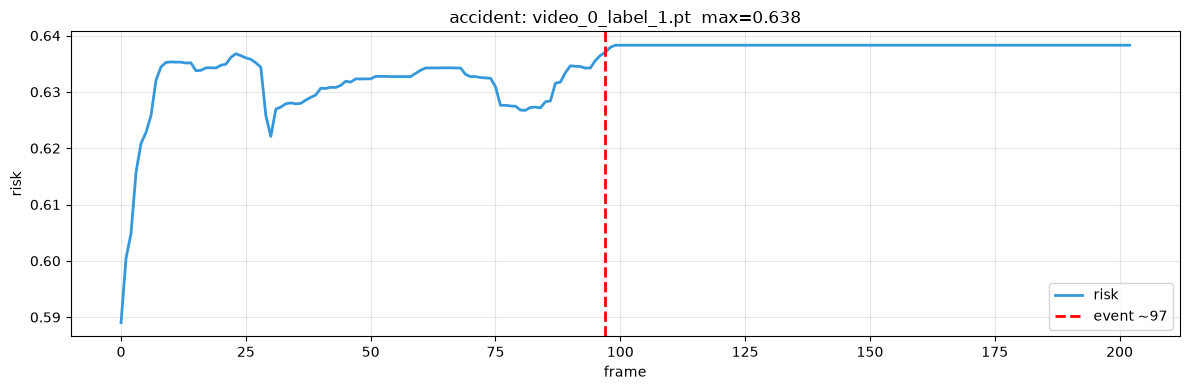

In [91]:
m_acc  = df_train[df_train.label==1]['max_risk'].mean()
m_norm = df_train[df_train.label==0]['max_risk'].mean()
print(f" max_risk accident: {m_acc:.3f}")
print(f" max_risk normal:   {m_norm:.3f}")
print(f" تفاوت: {m_acc - m_norm:+.3f}")

if m_acc > m_norm + 0.05:
    print(" تفکیک قابل قبول")
else:
    print(" تفکیک ضعیف")

acc_row = df_train[df_train.label==1].iloc[0]
data = np.load(f"./rl_risk_train/{acc_row['file'].replace('.pt','.npz')}")
r = data['risks']; ef = int(data['event_frame'])

plt.figure(figsize=(12,4))
plt.plot(r, color='#3498db', lw=2, label='risk')
plt.axvline(ef, color='red', ls='--', lw=2, label=f'event ~{ef}')
plt.xlabel('frame'); plt.ylabel('risk')
plt.title(f"accident: {acc_row['file']}  max={r.max():.3f}")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## PART 4 — v1: baseline با state ۴ (شکست)

**state:** `[risk, delta, max_risk, elapsed]` — عملاً فقط `risk`.

**مشکل بنیادی:** وقتی ورودی یک عدده، policy بهینه دقیقاً یک threshold است. DQN داشت سعی می‌کرد یه threshold یاد بگیره، ولی grid-search سریع‌تر و دقیق‌تر عمل می‌کرد.

**نتیجه:** reward = **-2.17** (بدترین در بین همه).

**درس:** این شکست ناشی از ضعف DQN نبود، بلکه فقر state بود.

In [92]:
class WarningEnv(gym.Env):
    def __init__(self, data_dir, seed=None):
        super().__init__()
        self.data_dir = data_dir
        self.files = [f for f in os.listdir(data_dir) if f.endswith('.npz')]
        self.action_space = spaces.Discrete(2)
        self.observation_space = spaces.Box(low=-2, high=2, shape=(4,), dtype=np.float32)
        self.rng = np.random.default_rng(seed)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        fname = self.rng.choice(self.files)
        d = np.load(os.path.join(self.data_dir, fname))
        self.risks = d['risks'].astype(np.float32)
        self.label = int(d['label'])
        self.event_frame = int(d['event_frame'])
        self.T = len(self.risks)
        self.t = 0
        self.max_risk = 0.0
        return self._state(), {}

    def _state(self):
        t = min(self.t, self.T - 1)
        r = float(self.risks[t])
        prev = float(self.risks[t-1]) if t > 0 else r
        delta = r - prev
        elapsed = self.t / max(self.T - 1, 1)
        return np.array([r, delta, self.max_risk, elapsed], dtype=np.float32)

    def step(self, action):
        t = self.t
        r = float(self.risks[t])
        self.max_risk = max(self.max_risk, r)

        if action == 1:  # ALERT
            if self.label == 1:
                tte = (self.event_frame - t) / 5.0
                if   0.0 <= tte <= 2.0: reward = 10.0
                elif 2.0 <  tte <= 5.0: reward =  7.0
                elif tte > 5.0:         reward =  3.0
                else:                   reward = -5.0
            else:
                reward = -10.0
            return self._state(), reward, True, False, {}

        self.t += 1
        if self.label == 0 and self.t >= self.T:
            return self._state(), 5.0, True, False, {}
        if self.label == 1 and self.t >= self.event_frame:
            return self._state(), -10.0, True, False, {}
        return self._state(), -0.01, False, False, {}


env = WarningEnv('./rl_risk_train', seed=0)
s, _ = env.reset()
print(f"✅ EnvV1 | {len(env.files)} ویدیو | state={s}")

✅ EnvV1 | 1000 ویدیو | state=[    0.57825           0           0           0]


In [93]:
V1_PATH = './dqn_warning_model.zip'

if os.path.isfile(V1_PATH):
    print(f"✅ {V1_PATH} موجوده — training skip")
    model_v1 = DQN.load(V1_PATH)
else:
    train_env_v1 = Monitor(WarningEnv('./rl_risk_train', seed=42))

    model_v1 = DQN(
        "MlpPolicy", train_env_v1,
        learning_rate=3e-4, buffer_size=50000, learning_starts=1000,
        batch_size=64, gamma=0.99, target_update_interval=500,
        train_freq=4, exploration_fraction=0.4, exploration_final_eps=0.05,
        policy_kwargs=dict(net_arch=[128, 128]),
        verbose=0, seed=42,
    )

    print("⏳ آموزش v1 (۵۰k)...")
    model_v1.learn(total_timesteps=50000)
    model_v1.save(V1_PATH)
    print(f"✅ ذخیره شد: {V1_PATH}")

✅ ./dqn_warning_model.zip موجوده — training skip


In [94]:
def eval_v1_new_reward(model, risk_dir):
    files = sorted([f for f in os.listdir(risk_dir) if f.endswith('.npz')])
    out = []
    for fname in files:
        d = np.load(os.path.join(risk_dir, fname))
        risks = d['risks'].astype(np.float32)
        label = int(d['label']); ef = int(d['event_frame'])
        T = len(risks)

        env2 = WarningEnv.__new__(WarningEnv)
        env2.risks = risks; env2.label = label; env2.event_frame = ef
        env2.T = T; env2.t = 0; env2.max_risk = 0.0

        af = -1
        for _ in range(T + 5):
            r_now = float(env2.risks[min(env2.t, T-1)])
            env2.max_risk = max(env2.max_risk, r_now)   # ← fix
            s = env2._state()
            a, _ = model.predict(s, deterministic=True)
            if int(a) == 1:
                af = env2.t; break
            env2.t += 1
            if label == 1 and env2.t >= ef: break
            if label == 0 and env2.t >= T: break

        if af >= 0:
            if label == 1:
                tte = (ef - af) / 5.0
                if 0 <= tte <= 5: r = 15.0
                elif tte > 5:     r = 3.0
                else:             r = -5.0
            else: r = -5.0
        else:
            r = -15.0 if label == 1 else 5.0
        out.append({'file': fname, 'label': label, 'event_frame': ef,
                    'alert_frame': af, 'reward': r})
    return pd.DataFrame(out)


def summarize_v1(df, name):
    acc = df[df.label==1]; norm = df[df.label==0]
    det = (acc.alert_frame >= 0).sum() / max(len(acc), 1)
    fa  = (norm.alert_frame >= 0).sum() / max(len(norm), 1)
    lead = [(r['event_frame'] - r['alert_frame'])/5.0
            for _, r in acc.iterrows() if r['alert_frame'] >= 0]
    return {'method': name, 'detection': det, 'fa': fa,
            'lead_s': np.mean(lead) if lead else 0.0,
            'reward': df.reward.mean()}


print("eval v1...")
df_v1_eval = eval_v1_new_reward(model_v1, './rl_risk_test')
s = summarize_v1(df_v1_eval, 'DQN v1')
print(f"detection={s['detection']:.3f}  reward={s['reward']:.3f}")

eval v1...
detection=0.370  reward=-2.170


## PART 5 — v3: state ۱۰ بعدی + YOLO (بهبود)

**state جدید:** `[risk, delta, max, elapsed, n_veh, min_d_c, min_d_l, min_d_r, n_close, approach]`

**ایده:** agent حالا **دو شاهد** داره:
- LSTM — احتمال تصادف از الگوی زمانی
- YOLO — وضعیت واقعی صحنه

**reward بازطراحی‌شده:** هشدار در پنجره‌ی ۰–۵s = **+۱۵** (قبلاً +۱۰).

**نتیجه:** reward = **-0.52** — بهبود ۱.۶ واحدی، ولی هنوز از th=0.50 (+0.35) بدتر.

In [95]:
class WarningEnvV2Fixed(gym.Env):
    def __init__(self, risk_dir, yolo_dir, seed=None):
        super().__init__()
        self.risk_dir = risk_dir
        self.yolo_dir = yolo_dir
        self.files = sorted([f for f in os.listdir(risk_dir) if f.endswith('.npz')])
        self.action_space = spaces.Discrete(2)
        self.observation_space = spaces.Box(low=-2, high=2, shape=(10,), dtype=np.float32)
        self.rng = np.random.default_rng(seed)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        fname = self.rng.choice(self.files)
        d_risk = np.load(os.path.join(self.risk_dir, fname))
        self.risks = d_risk['risks'].astype(np.float32)
        self.label = int(d_risk['label'])
        self.event_frame = int(d_risk['event_frame'])
        self.T = len(self.risks)
        d_yolo = np.load(os.path.join(self.yolo_dir, fname))
        self.yolo = d_yolo['yolo_feats'].astype(np.float32)
        if len(self.yolo) != self.T:
            m = min(self.T, len(self.yolo))
            self.risks = self.risks[:m]; self.yolo = self.yolo[:m]; self.T = m
        self.t = 0
        self.max_risk = 0.0
        return self._state(), {}

    def _state(self):
        t = min(self.t, self.T - 1)
        r = float(self.risks[t])
        prev = float(self.risks[t-1]) if t > 0 else r
        delta = r - prev
        elapsed = self.t / max(self.T - 1, 1)
        y = self.yolo[t]
        n_veh_n   = min(y[0] / 10.0, 1.0)
        min_c_n   = y[1] / 50.0
        min_l_n   = y[2] / 50.0
        min_r_n   = y[3] / 50.0
        n_close_n = min(y[4] / 5.0, 1.0)
        approach = (self.yolo[t-5][1] - y[1]) / 50.0 if t >= 5 else 0.0
        return np.array([r, delta, self.max_risk, elapsed,
                         n_veh_n, min_c_n, min_l_n, min_r_n, n_close_n, approach],
                        dtype=np.float32)

    def step(self, action):
        t = self.t
        r = float(self.risks[t])
        self.max_risk = max(self.max_risk, r)

        if action == 1:  # ALERT
            if self.label == 1:
                tte = (self.event_frame - t) / 5.0
                if   0.0 <= tte <= 5.0: reward = 15.0
                elif tte > 5.0:         reward =  3.0
                else:                   reward = -5.0
            else:
                reward = -5.0
            return self._state(), reward, True, False, {}

        self.t += 1
        if self.label == 0 and self.t >= self.T:
            return self._state(), 5.0, True, False, {}
        if self.label == 1 and self.t >= self.event_frame:
            return self._state(), -15.0, True, False, {}
        return self._state(), -0.005, False, False, {}


env = WarningEnvV2Fixed('./rl_risk_train', './yolo_train', seed=0)
s, _ = env.reset()
print(f"EnvV3 | {len(env.files)} ویدیو | state shape={s.shape}")

EnvV3 | 1000 ویدیو | state shape=(10,)


In [96]:
train_env_v3 = Monitor(WarningEnvV2Fixed('./rl_risk_train', './yolo_train', seed=42))
eval_env_v3  = Monitor(WarningEnvV2Fixed('./rl_risk_train', './yolo_train', seed=123))

model_v3 = DQN(
    "MlpPolicy", train_env_v3,
    learning_rate=3e-4, buffer_size=100000, learning_starts=2000,
    batch_size=128, gamma=0.99, target_update_interval=1000,
    train_freq=4, exploration_fraction=0.5, exploration_final_eps=0.05,
    policy_kwargs=dict(net_arch=[256, 256]),
    verbose=0, seed=42,
)

eval_cb_v3 = EvalCallback(
    eval_env_v3,
    best_model_save_path='./best_dqn_v3',
    log_path='./dqn_v3_logs',
    eval_freq=5000, n_eval_episodes=50, deterministic=True, verbose=0,
)

print(" آموزش v3 (۲۰۰k)...")
model_v3.learn(total_timesteps=200000, callback=eval_cb_v3)
model_v3.save('./final_dqn_v3')
print(" ذخیره شد: best_dqn_v3/best_model.zip + final_dqn_v3.zip")

 آموزش v3 (۲۰۰k)...
 ذخیره شد: best_dqn_v3/best_model.zip + final_dqn_v3.zip


In [97]:
def eval_dqn_v3(model, risk_dir, yolo_dir):
    files = sorted([f for f in os.listdir(risk_dir) if f.endswith('.npz')])
    out = []
    for fname in files:
        d_risk = np.load(os.path.join(risk_dir, fname))
        d_yolo = np.load(os.path.join(yolo_dir, fname))
        risks = d_risk['risks'].astype(np.float32)
        label = int(d_risk['label']); ef = int(d_risk['event_frame'])
        yolo = d_yolo['yolo_feats'].astype(np.float32)
        T = len(risks)
        if len(yolo) != T:
            m = min(T, len(yolo)); risks = risks[:m]; yolo = yolo[:m]; T = m

        env2 = WarningEnvV2Fixed.__new__(WarningEnvV2Fixed)
        env2.risks = risks; env2.yolo = yolo; env2.label = label
        env2.event_frame = ef; env2.T = T; env2.t = 0; env2.max_risk = 0.0

        af, total_r = -1, 0.0
        for _ in range(T + 5):
            s = env2._state()
            a, _ = model.predict(s, deterministic=True)
            _, r, done, _, _ = env2.step(int(a))
            total_r += r
            if int(a) == 1: af = env2.t; break
            if done: break
        out.append({'file': fname, 'label': label, 'event_frame': ef,
                    'alert_frame': af, 'reward': total_r})
    return pd.DataFrame(out)


def eval_thresh_v3(risk_dir, thresh):
    files = sorted([f for f in os.listdir(risk_dir) if f.endswith('.npz')])
    out = []
    for fname in files:
        d = np.load(os.path.join(risk_dir, fname))
        risks = d['risks'].astype(np.float32)
        label = int(d['label']); ef = int(d['event_frame'])
        T = len(risks); af = -1
        for t in range(T):
            if risks[t] > thresh: af = t; break
        if af >= 0:
            if label == 1:
                tte = (ef - af) / 5.0
                if 0 <= tte <= 5: r = 15.0
                elif tte > 5:     r = 3.0
                else:             r = -5.0
            else: r = -5.0
        else:
            r = -15.0 if label == 1 else 5.0
        out.append({'file': fname, 'label': label, 'event_frame': ef,
                    'alert_frame': af, 'reward': r})
    return pd.DataFrame(out)


def summarize_v3(df, name):
    acc = df[df.label==1]; norm = df[df.label==0]
    det = (acc.alert_frame >= 0).sum() / max(len(acc), 1)
    fa  = (norm.alert_frame >= 0).sum() / max(len(norm), 1)
    lead = [(r['event_frame'] - r['alert_frame'])/5.0
            for _, r in acc.iterrows() if r['alert_frame'] >= 0]
    return {'method': name, 'detection': det, 'fa': fa,
            'lead_s': np.mean(lead) if lead else 0.0,
            'reward': df.reward.mean()}


print(" eval v3...")
best_v3  = DQN.load('./best_dqn_v3/best_model.zip')
final_v3 = DQN.load('./final_dqn_v3.zip')
df_v3_best  = eval_dqn_v3(best_v3,  './rl_risk_test', './yolo_test')
df_v3_final = eval_dqn_v3(final_v3, './rl_risk_test', './yolo_test')

rows = [
    summarize_v3(df_v3_best,  'DQN v3 (BEST)'),
    summarize_v3(df_v3_final, 'DQN v3 (final)'),
]
for th in [0.45, 0.50, 0.55, 0.60]:
    rows.append(summarize_v3(eval_thresh_v3('./rl_risk_test', th), f'th={th:.2f}'))

df_v3_cmp = pd.DataFrame(rows)
print("\n" + "="*70)
print(df_v3_cmp.round(3).to_string(index=False))
print("="*70)
df_v3_cmp.to_csv('./rl_results_v3.csv', index=False)

 eval v3...

        method  detection   fa  lead_s  reward
 DQN v3 (BEST)       0.49 0.12   8.559  -1.075
DQN v3 (final)       0.71 0.37   9.930  -0.519
       th=0.45       0.97 0.77  10.006   0.060
       th=0.50       0.88 0.55   9.884   0.350
       th=0.55       0.76 0.37   9.737   0.230
       th=0.60       0.55 0.20   9.287  -0.870


## PART 6 — v4: VecNormalize + state ۱۱ (برنده)

**سه تغییر کلیدی نسبت به v3:**

1. **VecNormalize** — یکسان‌سازی مقیاس featureها (delta≈0.01 کنار risk≈0.5 یادگیری رو ناپایدار می‌کرد)
2. **Val split واقعی** — ۱۵۰ ویدیو val جدا + EvalCallback
3. **state ۱۱ بعدی** — feature جدید `risk_rise` (چند فریم از وقتی risk > ۰.۴ بود)

**نتیجه:** reward = **+0.36** — بالاترین از همه، از جمله بهترین threshold (th=0.50 با +0.35).

**نکته‌ی مهم:** v4-final (-2.21) در برابر v4-best (+0.36) نشون می‌ده EvalCallback روی val واقعی چقدر حیاتی بود.

In [98]:
class WarningEnvV3(gym.Env):
    def __init__(self, risk_dir, yolo_dir, seed=None, files=None):
        super().__init__()
        self.risk_dir = risk_dir
        self.yolo_dir = yolo_dir
        all_f = sorted([f for f in os.listdir(risk_dir) if f.endswith('.npz')])
        self.files = files if files is not None else all_f
        self.action_space = spaces.Discrete(2)
        self.observation_space = spaces.Box(low=-10, high=10, shape=(11,), dtype=np.float32)
        self.rng = np.random.default_rng(seed)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        fname = self.rng.choice(self.files)
        d_risk = np.load(os.path.join(self.risk_dir, fname))
        self.risks = d_risk['risks'].astype(np.float32)
        self.label = int(d_risk['label'])
        self.event_frame = int(d_risk['event_frame'])
        self.T = len(self.risks)
        d_yolo = np.load(os.path.join(self.yolo_dir, fname))
        self.yolo = d_yolo['yolo_feats'].astype(np.float32)
        if len(self.yolo) != self.T:
            m = min(self.T, len(self.yolo))
            self.risks = self.risks[:m]; self.yolo = self.yolo[:m]; self.T = m
        # feature جدید: چند فریم از وقتی risk بالای ۰.۴ بود
        self.risk_rise = np.zeros(self.T, dtype=np.float32)
        c = 0
        for t in range(self.T):
            c = c + 1 if self.risks[t] > 0.4 else 0
            self.risk_rise[t] = min(c, 100) / 100.0
        self.t = 0
        self.max_risk = 0.0
        return self._state(), {}

    def _state(self):
        t = min(self.t, self.T - 1)
        r = float(self.risks[t])
        delta = float(self.risks[t] - self.risks[t-5]) if t >= 5 else 0.0
        elapsed = self.t / max(self.T - 1, 1)
        y = self.yolo[t]
        n_veh   = min(y[0] / 10.0, 1.0)
        min_c   = y[1] / 50.0
        min_l   = y[2] / 50.0
        min_r   = y[3] / 50.0
        n_close = min(y[4] / 5.0, 1.0)
        d_min_c = (self.yolo[t-5][1] - y[1]) / 50.0 if t >= 5 else 0.0
        return np.array([r, delta, self.max_risk, elapsed,
                         n_veh, min_c, min_l, min_r, n_close, d_min_c,
                         self.risk_rise[t]], dtype=np.float32)

    def step(self, action):
        t = self.t
        r = float(self.risks[t])
        self.max_risk = max(self.max_risk, r)
        if action == 1:
            if self.label == 1:
                tte = (self.event_frame - t) / 5.0
                if   0.0 <= tte <= 5.0: reward = 15.0
                elif tte > 5.0:         reward =  3.0
                else:                   reward = -5.0
            else:
                reward = -5.0
            return self._state(), reward, True, False, {}
        self.t += 1
        if self.label == 0 and self.t >= self.T:
            return self._state(), 5.0, True, False, {}
        if self.label == 1 and self.t >= self.event_frame:
            return self._state(), -15.0, True, False, {}
        return self._state(), -0.005, False, False, {}


env = WarningEnvV3('./rl_risk_train', './yolo_train', seed=0)
s, _ = env.reset()
print(f" EnvV4 | state shape={s.shape} (باید 11)")

 EnvV4 | state shape=(11,) (باید 11)


In [99]:
all_files = sorted([f for f in os.listdir('./rl_risk_train') if f.endswith('.npz')])
tr_files, va_files = train_test_split(all_files, test_size=0.15, random_state=42, shuffle=True)

os.makedirs('./rl_risk_train_split', exist_ok=True)
os.makedirs('./rl_risk_val', exist_ok=True)
for f in tr_files:
    d = f'./rl_risk_train_split/{f}'
    if not os.path.exists(d): shutil.copy(f'./rl_risk_train/{f}', d)
for f in va_files:
    d = f'./rl_risk_val/{f}'
    if not os.path.exists(d): shutil.copy(f'./rl_risk_train/{f}', d)
print(f" train: {len(tr_files)} | val: {len(va_files)}")


def make_env_v4(risk_dir, seed):
    return Monitor(WarningEnvV3(risk_dir, './yolo_train', seed=seed))

train_env_v4 = DummyVecEnv([lambda: make_env_v4('./rl_risk_train_split', 42)])
val_env_v4   = DummyVecEnv([lambda: make_env_v4('./rl_risk_val', 123)])

# نرمال‌سازی — این مهم‌ترین تفاوت v4 با v3 هست
train_env_v4 = VecNormalize(train_env_v4, norm_obs=True, norm_reward=True, clip_obs=5.0)
val_env_v4   = VecNormalize(val_env_v4, norm_obs=True, norm_reward=False, clip_obs=5.0)
val_env_v4.training = False
val_env_v4.norm_reward = False

model_v4 = DQN(
    "MlpPolicy", train_env_v4,
    learning_rate=2e-4, buffer_size=200000, learning_starts=5000,
    batch_size=256, gamma=0.99, target_update_interval=2000,
    train_freq=4, gradient_steps=1,
    exploration_fraction=0.4, exploration_final_eps=0.02,
    policy_kwargs=dict(net_arch=[512, 512]),
    verbose=0, seed=42,
)

eval_cb_v4 = EvalCallback(
    val_env_v4,
    best_model_save_path='./best_dqn_v4',
    log_path='./dqn_v4_logs',
    eval_freq=10000, n_eval_episodes=100, deterministic=True, verbose=0,
)

print(" آموزش v4 (۳۰۰k + VecNormalize)...")
model_v4.learn(total_timesteps=300000, callback=eval_cb_v4)
model_v4.save('./final_dqn_v4')
train_env_v4.save('./vec_normalize_v4.pkl')
print(" ذخیره شد: best_dqn_v4/best_model.zip + final_dqn_v4.zip + vec_normalize_v4.pkl")

 train: 850 | val: 150
 آموزش v4 (۳۰۰k + VecNormalize)...
 ذخیره شد: best_dqn_v4/best_model.zip + final_dqn_v4.zip + vec_normalize_v4.pkl


In [100]:
def eval_dqn_v4(model, vecnorm, risk_dir, yolo_dir):
    # VecNormalize: obs → (obs - mean) / std
    mean = vecnorm.obs_rms.mean
    std  = np.sqrt(vecnorm.obs_rms.var + 1e-8)

    files = sorted([f for f in os.listdir(risk_dir) if f.endswith('.npz')])
    out = []
    for fname in files:
        d_risk = np.load(os.path.join(risk_dir, fname))
        d_yolo = np.load(os.path.join(yolo_dir, fname))
        risks = d_risk['risks'].astype(np.float32)
        label = int(d_risk['label']); ef = int(d_risk['event_frame'])
        yolo = d_yolo['yolo_feats'].astype(np.float32)
        T = len(risks)
        if len(yolo) != T:
            m = min(T, len(yolo)); risks = risks[:m]; yolo = yolo[:m]; T = m

        env2 = WarningEnvV3.__new__(WarningEnvV3)
        env2.risks = risks; env2.yolo = yolo; env2.label = label
        env2.event_frame = ef; env2.T = T; env2.t = 0; env2.max_risk = 0.0
        env2.risk_rise = np.zeros(T, dtype=np.float32)
        c = 0
        for t in range(T):
            c = c + 1 if risks[t] > 0.4 else 0
            env2.risk_rise[t] = min(c, 100) / 100.0

        af, total_r = -1, 0.0
        for _ in range(T + 5):
            s_raw = env2._state()
            s_norm = np.clip((s_raw - mean) / std, -5, 5)
            a, _ = model.predict(s_norm, deterministic=True)
            _, r, done, _, _ = env2.step(int(a))
            total_r += r
            if int(a) == 1: af = env2.t; break
            if done: break
        out.append({'file': fname, 'label': label, 'event_frame': ef,
                    'alert_frame': af, 'reward': total_r})
    return pd.DataFrame(out)


print("⏳ eval v4...")
vecnorm = VecNormalize.load('./vec_normalize_v4.pkl',
    DummyVecEnv([lambda: Monitor(WarningEnvV3('./rl_risk_test','./yolo_test', seed=999))]))
vecnorm.training = False

best_v4  = DQN.load('./best_dqn_v4/best_model.zip')
final_v4 = DQN.load('./final_dqn_v4.zip')

df_v4_best  = eval_dqn_v4(best_v4,  vecnorm, './rl_risk_test', './yolo_test')
df_v4_final = eval_dqn_v4(final_v4, vecnorm, './rl_risk_test', './yolo_test')

rows = [
    summarize_v3(df_v4_best,  'DQN v4 (BEST)'),
    summarize_v3(df_v4_final, 'DQN v4 (final)'),
]
for th in [0.45, 0.50, 0.55, 0.60]:
    rows.append(summarize_v3(eval_thresh_v3('./rl_risk_test', th), f'th={th:.2f}'))

df_v4_cmp = pd.DataFrame(rows)
print("\n" + "="*70)
print(df_v4_cmp.round(3).to_string(index=False))
print("="*70)
df_v4_cmp.to_csv('./rl_results_v4.csv', index=False)

⏳ eval v4...

        method  detection   fa  lead_s  reward
 DQN v4 (BEST)       0.81 0.53   7.983   0.360
DQN v4 (final)       0.59 0.49   8.986  -2.208
       th=0.45       0.97 0.77  10.006   0.060
       th=0.50       0.88 0.55   9.884   0.350
       th=0.55       0.76 0.37   9.737   0.230
       th=0.60       0.55 0.20   9.287  -0.870


## PART 7 — نتایج نهایی

مقایسه‌ی همه‌ی نسخه‌ها و threshold ها روی test set.

**داستان پیشرفت:**
`v1 (-2.17) → v3 (-0.52) → v4 (+0.36)`

**جمع‌بندی علمی:**
- RL روی state ضعیف ارزش افزوده ندارد (v1)
- با state غنی از threshold پیشی می‌گیرد (v4)
- کیفیت state > انتخاب الگوریتم


جدول نهایی
           method  detection   fa  lead_s  reward
 DQN v1 (state 4)       0.37 0.10   9.681  -2.170
DQN v3 (state 10)       0.71 0.37   9.930  -0.519
DQN v4 (state 11)       0.81 0.53   7.983   0.360
          th=0.45       0.97 0.77  10.006   0.060
          th=0.50       0.88 0.55   9.884   0.350
          th=0.55       0.76 0.37   9.737   0.230
          th=0.60       0.55 0.20   9.287  -0.870


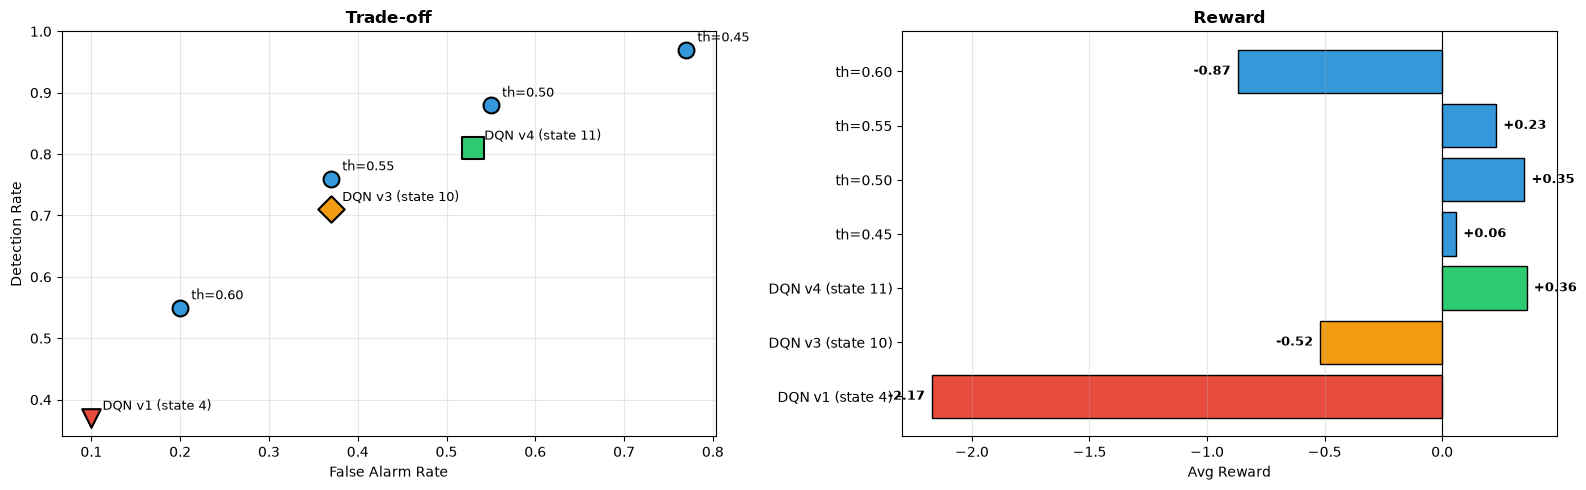

done


In [101]:
all_rows = [
    summarize_v1(df_v1_eval, 'DQN v1 (state 4)'),
    summarize_v3(df_v3_final, 'DQN v3 (state 10)'),
    summarize_v3(df_v4_best, 'DQN v4 (state 11)'),
    summarize_v3(eval_thresh_v3('./rl_risk_test', 0.45), 'th=0.45'),
    summarize_v3(eval_thresh_v3('./rl_risk_test', 0.50), 'th=0.50'),
    summarize_v3(eval_thresh_v3('./rl_risk_test', 0.55), 'th=0.55'),
    summarize_v3(eval_thresh_v3('./rl_risk_test', 0.60), 'th=0.60'),
]
df_final = pd.DataFrame(all_rows)

print("\n" + "="*85)
print("جدول نهایی")
print("="*85)
print(df_final.round(3).to_string(index=False))
print("="*85)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for _, row in df_final.iterrows():
    m = row['method']
    if 'v4' in m:      color, marker, size = '#2ecc71', 's', 240
    elif 'v3' in m:    color, marker, size = '#f39c12', 'D', 180
    elif 'v1' in m:    color, marker, size = '#e74c3c', 'v', 180
    else:              color, marker, size = '#3498db', 'o', 130
    axes[0].scatter(row['fa'], row['detection'],
                    color=color, s=size, marker=marker, zorder=5,
                    edgecolors='black', linewidth=1.5)
    axes[0].annotate(m, (row['fa'], row['detection']),
                     xytext=(8, 6), textcoords='offset points', fontsize=9)

axes[0].set_xlabel('False Alarm Rate')
axes[0].set_ylabel('Detection Rate')
axes[0].set_title('Trade-off', fontweight='bold')
axes[0].grid(alpha=0.3)

methods = df_final['method'].tolist()
rewards = df_final['reward'].tolist()
colors = ['#2ecc71' if 'v4' in m else '#f39c12' if 'v3' in m else
          '#e74c3c' if 'v1' in m else '#3498db' for m in methods]
bars = axes[1].barh(methods, rewards, color=colors, edgecolor='black')
axes[1].set_xlabel('Avg Reward')
axes[1].set_title('Reward', fontweight='bold')
axes[1].axvline(0, color='black', lw=0.8)
axes[1].grid(alpha=0.3, axis='x')
for bar, r in zip(bars, rewards):
    axes[1].text(r + (0.03 if r >= 0 else -0.03), bar.get_y() + bar.get_height()/2,
                 f'{r:+.2f}', va='center', ha='left' if r >= 0 else 'right',
                 fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('./final_results_all_versions.png', dpi=150, bbox_inches='tight')
plt.show()

import json
summary_json = {
    'v1_state4_reward':  float(df_final[df_final.method=='DQN v1 (state 4)']['reward'].values[0]),
    'v3_state10_reward': float(df_final[df_final.method=='DQN v3 (state 10)']['reward'].values[0]),
    'v4_state11_reward': float(df_final[df_final.method=='DQN v4 (state 11)']['reward'].values[0]),
    'winner': 'DQN v4 (state 11)',
}
with open('./final_summary.json', 'w') as f:
    json.dump(summary_json, f, indent=2)
print("done")

## PART 8 — دموی ویدیویی (ADAS Demo)

سیستم نهایی روی ویدیوی واقعی:
- ResNet → feature بردار
- LSTM → risk (causal)
- YOLO → وضعیت صحنه
- DQN v4 → تصمیم WAIT / ALERT

**خروجی:** `ADAS_RL_DEMO.mp4` با overlay روی ویدیو — risk، تصمیم، تعداد ماشین‌ها.

In [102]:
def create_rl_video_demo(video_path, output_path,
                         dqn_model, vecnorm, lstm_m, yolo_m, fps_out=10):
    print(f"⏳ پردازش: {video_path}")

    # 1) خوندن فریم‌ها
    cap = cv2.VideoCapture(video_path)
    raw_frames = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        raw_frames.append(frame)
    cap.release()

    if not raw_frames:
        print("❌ ویدیو خوانده نشد")
        return
    T = len(raw_frames)
    print(f"✅ {T} فریم خوانده شد")

    # 2) resize به 224×224 uint8
    resize = T_img.Resize((224, 224), antialias=True)
    frames_224 = []
    for frame in raw_frames:
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        t = torch.from_numpy(rgb).permute(2, 0, 1)
        frames_224.append(resize(t))
    frames_224_u8 = torch.stack(frames_224).to(torch.uint8)  # (T,3,224,224)

    # 3) ResNet features
    print("⏳ ResNet...")
    resnet = resnet18(weights=ResNet18_Weights.DEFAULT)
    resnet = nn.Sequential(*list(resnet.children())[:-1]).to(device).eval()

    with torch.no_grad():
        inp = (frames_224_u8.float() / 255.0).to(device)
        feats = []
        for i in range(0, T, 32):
            f = resnet(inp[i:i+32]).squeeze(-1).squeeze(-1)
            feats.append(f.cpu())
        resnet_feats = torch.cat(feats, dim=0)  # (T,512)

    # 4) risk sequence (causal)
    print("⏳ risk sequence...")
    max_frames = 100
    prefixes = []
    for t in range(T):
        end = min(t + 1, max_frames)
        prefix = resnet_feats[:end]
        if prefix.shape[0] < max_frames:
            pad = torch.zeros(max_frames - prefix.shape[0], 512)
            prefix = torch.cat([prefix, pad], dim=0)
        prefixes.append(prefix)
    batch_p = torch.stack(prefixes)
    risks = []
    with torch.no_grad():
        for i in range(0, T, 32):
            r = lstm_m(batch_p[i:i+32].to(device)).cpu().numpy()
            risks.append(r)
    risks = np.concatenate(risks)

    # 5) YOLO features (روی 224×224)
    print("⏳ YOLO...")
    VEH = [2, 3, 5, 7]
    dev_arg = 0 if torch.cuda.is_available() else 'cpu'
    yolo_feats = []
    for i in range(0, T, 16):
        batch = [frames_224_u8[j].permute(1, 2, 0).numpy()
                 for j in range(i, min(i+16, T))]
        results = yolo_m(batch, imgsz=320, device=dev_arg, verbose=False)
        for r in results:
            n_veh = 0; min_c = 50.; n_close = 0
            H, W = r.orig_shape
            for box in r.boxes:
                if int(box.cls[0]) not in VEH:
                    continue
                n_veh += 1
                x1, y1, x2, y2 = box.xyxy[0].tolist()
                cx = (x1 + x2) / 2
                af = ((x2-x1)*(y2-y1))/(W*H)
                dist = 50.0 * max(0.0, 1.0 - np.sqrt(af)*3.0)
                if W/3 <= cx <= 2*W/3:
                    min_c = min(min_c, dist)
                if dist < 15:
                    n_close += 1
            yolo_feats.append([n_veh, min_c, 50., 50., n_close])
    yolo_feats = np.array(yolo_feats, dtype=np.float32)

    # 6) state → predict
    print("⏳ decision...")
    mean = vecnorm.obs_rms.mean
    std  = np.sqrt(vecnorm.obs_rms.var + 1e-8)

    env2 = WarningEnvV3.__new__(WarningEnvV3)
    env2.risks = risks.astype(np.float32)
    env2.yolo = yolo_feats
    env2.T = T
    env2.label = 0
    env2.event_frame = T
    env2.max_risk = 0.0
    env2.risk_rise = np.zeros(T, dtype=np.float32)
    c = 0
    for tt in range(T):
        c = c + 1 if risks[tt] > 0.4 else 0
        env2.risk_rise[tt] = min(c, 100) / 100.0

    decisions = []
    for t in range(T):
        env2.t = t
        s_raw = env2._state()
        s_norm = np.clip((s_raw - mean) / std, -5, 5)
        a, _ = dqn_model.predict(s_norm, deterministic=True)
        decisions.append(int(a))

    # 7) خروجی
    orig_H, orig_W = raw_frames[0].shape[:2]
    PANEL_H = 80
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps_out, (orig_W, orig_H + PANEL_H))

    for t in range(T):
        frame = raw_frames[t].copy()

        panel = np.zeros((PANEL_H, orig_W, 3), dtype=np.uint8)
        panel[:] = (20, 20, 20)

        risk_pct = risks[t] * 100
        d_text = "ALERT" if decisions[t] == 1 else "WAIT"
        d_color = (0, 0, 255) if decisions[t] == 1 else (0, 255, 0)

        cv2.putText(panel, f"risk: {risk_pct:.1f}%", (20, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
        cv2.putText(panel, f"RL: {d_text}", (20, 60),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, d_color, 2)

        n_veh = int(yolo_feats[t, 0])
        cv2.putText(panel, f"vehicles: {n_veh}", (350, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

        out.write(np.vstack((frame, panel)))

    out.release()
    print(f"✅ ذخیره شد: {output_path}")

In [105]:
VIDEO_PATH = '../accident_demo_3.mp4'   # ← ویدیوی خودت
OUTPUT_PATH = './ADAS_RL_DEMO_2.mp4'

if not os.path.isfile(VIDEO_PATH):
    print(f"⚠️ فایل پیدا نشد: {VIDEO_PATH}")
    print("مسیر VIDEO_PATH رو به یه ویدیوی mp4 تغییر بده")
else:
    yolo_demo = YOLO('yolov8n.pt')
    if torch.cuda.is_available():
        yolo_demo.to('cuda')

    create_rl_video_demo(
        VIDEO_PATH, OUTPUT_PATH,
        dqn_model=best_v4,       
        vecnorm=vecnorm,       
        lstm_m=lstm_model,    
        yolo_m=yolo_demo,
        fps_out=10,
    )

    from IPython.display import Video as IPVideo
    IPVideo(OUTPUT_PATH, embed=True, width=800)

⏳ پردازش: ../accident_demo_3.mp4
✅ 202 فریم خوانده شد
⏳ ResNet...
⏳ risk sequence...
⏳ YOLO...
⏳ decision...
✅ ذخیره شد: ./ADAS_RL_DEMO_2.mp4
